# Self-supervised niches — KODIAK against its DINOv3 initialization

KODIAK (paper §4.2) continues the pretraining of a DINOv3 ViT-B/16 (`runs/kodiak_mxif_vitb`, the run of record) on the slide with three label-free objectives:
masked prediction of Sinkhorn-balanced **prototype** assignments (a codebook of 128 prototypes that every 16-px patch
token is assigned to), alignment of the multi-crop **CLS** token against the same codebook, and a uniformity term;
the EMA **teacher** is the encoder every segmentation experiment uses. The paper's argument is that the comparison
against the raw DINOv3 initialization isolates what slide-level pretraining contributed — so every figure here shows
the two encoders side by side: same regions, same input, same reading.

The reading follows the paper's fixed spatial pipeline (§4.5): expert cells → taxonomy gates → 10-cell windows →
$k$-means cellular neighborhoods, which gives the four reference niches (immune-infiltrated, epithelial core,
interface, stromal). The question is whether the structure the encoders find on their own — codes, code families,
tokens, CLS — is that structure.

| section | KODIAK vs DINOv3 on … |
|---|---|
| 1 | the held-out regions: tokens and codes as maps |
| 2 | the codebook's geometry: code families |
| 3 | what one code encodes (marker content, density, lineage) — and what a family looks like |
| 4 | families against the reference niches (agreement, maps) |
| 5 | what a token knows beyond its pixels (held-out-region linear probes) |
| 6 | the CLS token at slide scale |

DINOv3 has no codebook; a $k$-means with the same $K{=}128$, fit label-free on tokens of 400 training patches, stands
in for it. Notebook 01b asks the same question with the encoders matched (same k-means on both, probes with a
width control) on the test slide; this notebook keeps the codebook reading on the development slide's validation
regions. Everything runs on **CPU** from a copy of the newest checkpoint (the training run is untouched) and needs
`runs/kodiak_mxif_vitb/checkpoints/last.ckpt`, the DINOv3 ViT-B weights it started from (read from the run's
`resolved_config.yaml`) in `weights/` and the slide; the expert cell table
is computed here if notebook 10 has not written it. Figure text is kept to labels — the reading is in the captions.

In [1]:
# pick up edits to src/ without restarting the kernel
%load_ext autoreload
%autoreload 2
import json, os, shutil, tempfile, time
from pathlib import Path
import numpy as np, pandas as pd, torch, yaml
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import fcluster, leaves_list, linkage

from mxdata import DEFAULT_DATASET, load_config, load_regions, ingest
from mxdata.io import Box
from mxdata.data.composite import render_channels
from mxseg.evaluate import split_regions_of
from mxseg.inputs import dataset_norms
from kodiak import Kodiak
from kodiak.components import DinoV3Encoder

# ---- edit here ---------------------------------------------------------------------------------------------------------
RUN_NAME = "kodiak_mxif_vitb"                      # the pretraining run, found under runs_v2/ or runs/; its ARCHITECTURE and
#                                                    its DINOv3 initialization are read from the run itself, never set here
GREEN = "PanCK"                                    # the marker read into green for this analysis (pretraining drew it at random per sample)
CKPT = "last.ckpt"                                 # or a fixed one, e.g. "kodiak-epoch=099.ckpt"
SLIDE = "SLIDE-0235"                               # the slide analysed here: its regions, its codebook fit, its CLS map
SHOW = [13, 2]                                     # region ids drawn as maps; ones this slide does not have are dropped,
#                                                    and if none survive the first two regions of the split are used
K_FAM, K_CLS = 5, 5                                # code families per codebook; CLS clusters per encoder
# ------------------------------------------------------------------------------------------------------------------------

plt.rcParams.update({
    "figure.dpi": 135, "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "axes.labelsize": 8.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 2.6, "ytick.major.size": 2.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "legend.frameon": False, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.titlelocation": "left",
})
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ANALYSIS = REPO / "outputs" / "analysis"
cfg = load_config(REPO / "configs" / "dataset.yaml")

INK, MUTED, GRID = "#1A1C1F", "#6B7075", "#E4E6E9"
PHENO_COLOR = {"Epithelial": "#2A78D6", "Immune": "#C43E4E", "Other": "#AEB2B8"}
NICHE_COLOR = {"Immune-infiltrated": "#C43E4E", "Epithelial core": "#2A78D6",       # the paper's four reference niches
               "Interface": "#9A86E0", "Stromal / other": "#B9BDC4"}
PALETTE = ["#2A78D6", "#6FB1E0", "#9A86E0", "#C43E4E", "#B9BDC4", "#E4A72E", "#1BAF7A"]   # families / clusters, by rank
ENC_COLOR = {"KODIAK": "#C43E4E", "DINOv3": "#B08A2E"}
CHIP = dict(boxstyle="round,pad=0.22", fc="black", ec="none", alpha=0.6)

def panel(ax, letter, dx=-0.04, dy=1.04):
    """Nature-style bold panel letter, outside the axes' top-left corner."""
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=11.5, fontweight="bold", va="bottom", ha="right", color=INK)

def chip(ax, text):
    """A short label inside an image panel (region, markers, encoder) — never a sentence."""
    ax.text(0.015, 0.965, text, transform=ax.transAxes, fontsize=7.2, fontweight="bold", color="white", va="top", bbox=CHIP)

def ygrid(ax):
    ax.grid(axis="y", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def hex2rgb(h):
    return np.array([int(h[i:i + 2], 16) / 255 for i in (1, 3, 5)])

def short(key):
    return key.split("_")[-1]

def heat(ax, df):
    """Column-scaled heatmap with the raw numbers written in (profiles of families and clusters)."""
    vals = df.values.astype(float)
    norm = vals / np.maximum(vals.max(0, keepdims=True), 1e-9)
    ax.imshow(norm, cmap="magma", vmin=0, vmax=1, aspect="auto")
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            v = vals[i, j]
            ax.text(j, i, f"{v:.2f}" if v < 10 else f"{v:.0f}", ha="center", va="center", fontsize=6.6,
                    color="white" if norm[i, j] < 0.55 else "black")
    ax.set_xticks(range(vals.shape[1]), df.columns, fontsize=6.8, rotation=30, ha="right")
    ax.set_yticks(range(vals.shape[0]), df.index, fontsize=7.4)
    for s_ in ax.spines.values():
        s_.set_visible(False)
    ax.tick_params(length=0)

# ---- the two encoders: KODIAK's EMA teacher from a copy of the checkpoint, and the DINOv3 weights it started from --------
torch.set_grad_enabled(False)
torch.set_num_threads(max(2, (os.cpu_count() or 8) // 2))                      # CPU only: the GPU belongs to the training run
RUN = next((p for p in (REPO / "runs_v2" / RUN_NAME, REPO / "runs" / RUN_NAME) if p.is_dir()), None)
if RUN is None:
    raise FileNotFoundError(f"no run {RUN_NAME!r} under runs_v2/ or runs/ — pretrain first "
                            "(python -m kodiak.pretrain -c configs/kodiak_pretrain[_vitb].yaml)")
run_cfg = yaml.safe_load((RUN / "resolved_config.yaml").read_text())
M = run_cfg["model"]                                                        # THE ENCODER, exactly as this run was configured:
ARCH = dict(patch_size=M.get("vit_patch_size", 16), embed_dim=M.get("vit_embed_dim", 384),      # ViT-S/16 or ViT-B/16 — the same
            depth=M.get("vit_depth", 12), num_heads=M.get("vit_heads", 6),                      # keys kodiak.pretrain.build
            mlp_ratio=M.get("vit_mlp_ratio", 4.0), num_storage_tokens=M.get("num_storage_tokens", 4))   # reads, so the notebook
D = ARCH["embed_dim"]                                                       # token width: 384 (ViT-S) or 768 (ViT-B)
DEC = dict(decoder_embed_dim=M.get("decoder_dim", 192), decoder_depth=M.get("decoder_depth", 4),        # and the run cannot disagree
           decoder_num_heads=M.get("decoder_heads", 6))
CHANNELS = (run_cfg["data"]["input"]["red"], GREEN, run_cfg["data"]["input"]["blue"])   # R, G, B markers of the image analysed here
MARKERS = [m for m in CHANNELS if m]

src_ckpt, tmp_ckpt = RUN / "checkpoints" / CKPT, Path(tempfile.gettempdir()) / "niches_kodiak.ckpt"
if not src_ckpt.is_file():
    have = sorted(x.name for x in (RUN / "checkpoints").glob("*.ckpt")) if (RUN / "checkpoints").is_dir() else []
    raise FileNotFoundError(f"{src_ckpt.relative_to(REPO)} not found (checkpoints written every "
                            f"{run_cfg.get('training', {}).get('checkpoint', {}).get('every_n_epochs', 1)} epochs); have: {have}")
for attempt in range(3):                           # last.ckpt is rewritten at every epoch end: copy, and retry if caught mid-write
    try:
        shutil.copy2(src_ckpt, tmp_ckpt)
        ck = torch.load(tmp_ckpt, map_location="cpu", weights_only=False)
        break
    except Exception:
        if attempt == 2:
            raise
        time.sleep(5)
EPOCH = int(ck["epoch"])
kodiak = Kodiak(num_prototypes=M.get("num_prototypes", 128), projector_dim=M.get("projector_dim", 256),
                img_size=M.get("image_size", 256), **ARCH, **DEC).eval()
state = {k.split("model.", 1)[1]: v for k, v in ck["state_dict"].items() if k.startswith("model.")}
missing, _ = kodiak.load_state_dict(state, strict=False)
assert not [m for m in missing if "teacher" in m or "prototype" in m], missing   # what we inspect must load completely

WEIGHTS = REPO / M["pretrained_path"]              # the DINOv3 this run started from: the same architecture by construction
dino = DinoV3Encoder(**ARCH).eval()
dstate = torch.load(WEIGHTS, map_location="cpu", weights_only=False)
dino.load_state_dict(dstate.get("model", dstate), strict=True)

ENC = {"KODIAK": dict(fn=lambda xb: kodiak.forward_features(xb, use_teacher=True),          # -> (patch tokens, prototype logits)
                      cls=lambda xb: kodiak.teacher_encoder.forward_full(xb)[0], color=ENC_COLOR["KODIAK"]),
       "DINOv3": dict(fn=lambda xb: [dino.forward_full(xb)[1]],                              # -> [patch tokens]
                      cls=lambda xb: dino.forward_full(xb)[0], color=ENC_COLOR["DINOv3"])}

# ---- the exact pretraining input: the marker stack with the run's slide-level normalization -----------------------------
paths, mx, _ = ingest(SLIDE, None)
NORMS = dataset_norms(DEFAULT_DATASET, cfg.slides, MARKERS)[SLIDE]                 # the dataset's stored slide statistics, as in the run
IN_MEAN = np.array([0.485, 0.456, 0.406], np.float32)[:, None, None]
IN_STD = np.array([0.229, 0.224, 0.225], np.float32)[:, None, None]
G = ARCH["patch_size"]                                                         # token edge in pixels (16 for these ViTs)
PX_UM = float(mx.pixel_size_um or 0.325)

def composite(stack):
    """(C, H, W) uint16 in MARKERS order -> the network input with GREEN in the green channel."""
    return render_channels(stack, MARKERS, NORMS, CHANNELS)

def to_input(rgb):
    return ((rgb - IN_MEAN) / IN_STD).astype(np.float32)

def marker01(stack):
    """Each marker on its own slide-level [0, 1] scale."""
    return np.stack([np.clip((stack[c].astype(np.float32) - lo) / max(hi - lo, 1e-6), 0, 1)
                     for c, (lo, hi) in enumerate(NORMS[m] for m in MARKERS)])

def encode_windows(x, fn, size=256, stride=128, batch=8):
    """Token-grid outputs of a (3, H, W) input (H, W multiples of 16) from 256^2 windows on a 128-px lattice — the
    training resolution — blended where windows overlap with a Hann weight (no seams at window borders).
    fn: (B, 3, 256, 256) tensor -> sequence of (B, 256, d) outputs; returns one (H/16, W/16, d) array per output."""
    H, W = x.shape[1:]
    ys = sorted({*range(0, H - size + 1, stride), H - size})
    xs = sorted({*range(0, W - size + 1, stride), W - size})
    wins = [(y, xx) for y in ys for xx in xs]
    g = size // G
    hann = np.hanning(g + 2)[1:-1]
    wgt = (np.outer(hann, hann) + 1e-3)[..., None].astype(np.float32)
    acc, cnt = None, np.zeros((H // G, W // G, 1), np.float32)
    for i in range(0, len(wins), batch):
        chunk = wins[i:i + batch]
        outs = [o.numpy() for o in fn(torch.from_numpy(np.stack([x[:, y:y + size, xx:xx + size] for y, xx in chunk])))]
        if acc is None:
            acc = [np.zeros((H // G, W // G, o.shape[-1]), np.float32) for o in outs]
        for j, (y, xx) in enumerate(chunk):
            ty, tx = y // G, xx // G
            for a, o in zip(acc, outs):
                a[ty:ty + g, tx:tx + g] += o[j].reshape(g, g, -1) * wgt
            cnt[ty:ty + g, tx:tx + g] += wgt
    return [a / cnt for a in acc]

def scalebar(ax, w, h, um=100, color="white"):
    L = um / PX_UM
    x1, y = w * 0.97, h * 0.93
    ax.plot([x1 - L, x1], [y, y], color=color, lw=2.2, solid_capstyle="butt")
    ax.text(x1 - L / 2, y - h * 0.03, f"{um} µm", color=color, ha="center", va="bottom", fontsize=7)

print(f"KODIAK: {src_ckpt.relative_to(REPO)} @ epoch {EPOCH} (step {ck['global_step']}) | DINOv3: {WEIGHTS.name} | "
      f"ViT {ARCH['embed_dim']}d x {ARCH['depth']} x {ARCH['num_heads']}h, patch {ARCH['patch_size']} "
      f"({sum(p.numel() for p in dino.parameters()) / 1e6:.1f}M) | "
      f"input {MARKERS}, " + ", ".join(f"{m} {lo:.0f}-{hi:.0f}" for m, (lo, hi) in NORMS.items()))

KODIAK: runs/kodiak_mxif_vitb/checkpoints/last.ckpt @ epoch 65 (step 41448) | DINOv3: dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth | ViT 768d x 12 x 12h, patch 16 (85.7M) | input ['LAP2', 'PanCK', 'DAPI'], LAP2 88-8889, PanCK 0-12573, DAPI 132-5126


## 1. The held-out regions through both encoders

The regions of the slide's most held-out split (for the development slide the validation regions, kept out of
pretraining; for the test slide its test regions) are encoded whole by each encoder: 256² windows on a 128-px
lattice, tokens and prototype logits Hann-blended where windows overlap. Expert cells and their reference niches are
attached to the token grid: a token inherits the cells whose centroid it contains.

In [2]:
from scipy.spatial import cKDTree
from sklearn.cluster import MiniBatchKMeans

# The regions of SLIDE, from the most held-out split it has: under leave-slide-out the test split is the other slide, so for
# the development slide this is val (the regions kept out of pretraining), and for the test slide it is test.
by_split = {s: split_regions_of(DEFAULT_DATASET, s, cfg.slides).get(SLIDE, []) for s in ("test", "val", "train")}
SPLIT = next((s for s in ("test", "val", "train") if by_split[s]), None)
if SPLIT is None:
    raise ValueError(f"no labeled regions for {SLIDE} in {DEFAULT_DATASET}")
ids = sorted(by_split[SPLIT])
print(f"{SLIDE}: {len(ids)} {SPLIT} regions {ids}" + ("  (seen in pretraining)" if SPLIT == "train" else ""))
regions = {r.region_id: r for r in load_regions(paths, ids, cfg.min_area_px)}

# ---- DINOv3's stand-in codebook: k-means (K=128) on L2-normalized tokens of 400 random training patches -------------------
t0 = time.perf_counter()
pt_all = pd.read_csv(DEFAULT_DATASET / "patches.csv")
pt_all = pt_all[pt_all.kept.astype(bool) & (pt_all.slide == SLIDE)]
fit_rows = pt_all[pt_all.split == "train"].sample(400, random_state=0)
feats = []
for i in range(0, len(fit_rows), 16):
    rows = fit_rows.iloc[i:i + 16]
    stacks = [mx.read_region(Box(int(r.x0), int(r.y0), int(r.x1), int(r.y1)), markers=MARKERS, level=0) for r in rows.itertuples()]
    feats.append(dino.forward_full(torch.from_numpy(np.stack([to_input(composite(s)) for s in stacks])))[1].numpy().reshape(-1, D))
feats = np.concatenate(feats)
feats /= np.linalg.norm(feats, axis=1, keepdims=True)
kmq = MiniBatchKMeans(128, n_init=3, random_state=0, batch_size=4096).fit(feats)
print(f"DINOv3 stand-in codebook: k-means K=128 on {len(feats)} tokens of {len(fit_rows)} training patches ({time.perf_counter() - t0:.0f} s)")

def codebook_order(Wp):
    """A codebook's own geometry: the code vectors centered (the codebook's mean direction removed — DINOv3's centroids all
    share one, which would paint the whole matrix red) and normalized, their cosine similarity, Ward order (Euclidean on
    the sphere is monotone in cosine) and a hue per code so that similar codes share a color. ``Wn`` keeps the raw unit
    vectors, which is what code assignment uses."""
    Wn = Wp / np.linalg.norm(Wp, axis=1, keepdims=True)
    Wc = Wp - Wp.mean(0, keepdims=True)
    Wc /= np.linalg.norm(Wc, axis=1, keepdims=True)
    Z = linkage(Wc, method="ward")
    leaves = leaves_list(Z)
    pos = np.empty(len(Wn), int); pos[leaves] = np.arange(len(Wn))
    return dict(Wn=Wn, Wc=Wc, SIM=Wc @ Wc.T, Z=Z, leaves=leaves, pos=pos, cmap=plt.cm.turbo(pos / (len(Wn) - 1))[:, :3])

ENC["KODIAK"].update(codebook_order(kodiak.prototype_layer.layer.weight.numpy()))   # (128, 256): the learned prototypes
ENC["DINOv3"].update(codebook_order(kmq.cluster_centers_))                           # (128, D): the k-means centroids

# ---- the regions through both encoders ---------------------------------------------------------------------------------
t0 = time.perf_counter()
REG = {}
for rid, r in regions.items():
    key = f"{SLIDE}_R{rid:02d}"
    stack = mx.read_region(r.box, markers=MARKERS, level=0)
    H, W = (stack.shape[1] // G) * G, (stack.shape[2] // G) * G                # token-aligned crop (top-left anchored)
    stack = stack[:, :H, :W]
    rgb = composite(stack)
    R = dict(rgb=rgb.transpose(1, 2, 0), m01=marker01(stack), has_qc=r.has_qc)
    toks, logits = encode_windows(to_input(rgb), ENC["KODIAK"]["fn"])
    R["KODIAK"] = dict(toks=toks, logits=logits, codes=logits.argmax(-1))
    toks, = encode_windows(to_input(rgb), ENC["DINOv3"]["fn"])
    logits = (toks / np.linalg.norm(toks, axis=-1, keepdims=True)) @ ENC["DINOv3"]["Wn"].T   # cosine to every centroid
    R["DINOv3"] = dict(toks=toks, logits=logits, codes=logits.argmax(-1))
    REG[key] = R
SHOW = [k for k in (f"{SLIDE}_R{i:02d}" for i in SHOW) if k in REG] or list(REG)[:2]   # ids -> keys that exist
print(f"{len(REG)} regions x 2 encoders in {time.perf_counter() - t0:.0f} s: " +
      ", ".join(f"{short(k)} {v['KODIAK']['codes'].shape[1]}x{v['KODIAK']['codes'].shape[0]} tokens" for k, v in REG.items()))

# ---- expert cells and the reference niches: the paper's fixed pipeline (§4.5), the recipe of notebook 12 ------------------
CLASSES = ["Epithelial", "Immune", "Other"]
W_CN, NCN = 10, 4                                                              # 10-cell windows, four cellular neighborhoods

def load_expert_cells():
    """Marker means inside every scored expert cell, Otsu gates, the panel's phenotypes. Reuses a stored table only when it
    covers the regions analysed here — cells_expert.csv is written by notebooks 02-05 for the TEST slide, so a different slide
    is computed here the same way (no model involved) and cached per slide, leaving the shared table untouched."""
    need = set(REG)
    for f in (ANALYSIS / "cells_expert.csv", ANALYSIS / f"cells_expert_{SLIDE}.csv"):
        if f.is_file():
            e = pd.read_csv(f)
            if need <= set(e.region.unique()):
                return e[e.region.isin(need)].reset_index(drop=True)
    from mxdata import apply_qc_policy
    from mxdata.data import LiveSource
    from mxseg.analysis import assign_phenotypes, cell_marker_table, gate_phenotypes, load_panel, otsu_threshold, phenotype_gates
    PANEL = ["PanCK", "CD45", "CD3", "CD4", "CD8", "FOXP3", "uPAR"]
    live = LiveSource(mx, list(regions.values()), cfg.markers, cfg.level)
    frames = []
    for key in live.keys:
        rs = live.load(key)
        labels, ignore = apply_qc_policy(rs.labels, rs.flags, "ignore_wrong")
        gt = labels.copy()
        for g in np.unique(gt[ignore]):
            if g:
                gt[gt == g] = 0
        box = regions[int(key.split("_R")[-1])].box
        t = cell_marker_table(gt, mx.read_region(box, markers=PANEL, level=0).astype(np.float32), PANEL)
        t["region"] = key
        frames.append(t)
    e = pd.concat(frames, ignore_index=True)
    e["pheno"] = gate_phenotypes(e, {mk: otsu_threshold(e[mk]) for mk in ("PanCK", "CD45")})
    panel = load_panel(REPO / "configs" / "panel.yaml")
    e["cell_type"], e["lineage"] = assign_phenotypes(e, panel, phenotype_gates(e, panel))
    ANALYSIS.mkdir(parents=True, exist_ok=True)
    f = ANALYSIS / f"cells_expert_{SLIDE}.csv"                                  # never overwrites the shared test-slide table
    e.to_csv(f, index=False)
    print(f"expert cells computed here and saved to {f.relative_to(REPO)} ({len(e)} cells)")
    return e

expert = load_expert_cells()

def windows(cy, cx, pheno):
    """Schürch windows: frequency of each lineage among the W_CN nearest cells, the center included."""
    idx = {c: i for i, c in enumerate(CLASSES)}
    pts = np.column_stack([cy, cx])
    _, nn = cKDTree(pts).query(pts, k=min(W_CN, len(pts)))
    ph = np.array([idx[p] for p in pheno])
    comp = np.zeros((len(pts), len(CLASSES)))
    for i, row in enumerate(nn):
        for j in np.atleast_1d(row):
            comp[i, ph[j]] += 1
    return comp / np.maximum(comp.sum(1, keepdims=True), 1)

ecomp, frames = [], []
empty = [k for k in REG if not (expert.region == k).any()]
if empty:
    raise ValueError(f"no expert cells for {empty} — these regions carry no reviewed annotation in {DEFAULT_DATASET}")
for key in REG:
    e = expert[expert.region == key].reset_index(drop=True)
    ecomp.append(windows(e.cy.values, e.cx.values, list(e.pheno)))
    frames.append(e)
km = MiniBatchKMeans(NCN, n_init=10, random_state=0).fit(np.vstack(ecomp))
order = np.argsort(-km.cluster_centers_[:, CLASSES.index("Immune")])
NAME = {}
for rank_, cl in enumerate(order):
    cc = km.cluster_centers_[cl]
    NAME[cl] = ("Immune-infiltrated" if rank_ == 0 else "Epithelial core" if cc[CLASSES.index("Epithelial")] > 0.6
                else "Interface" if cc[CLASSES.index("Epithelial")] > 0.3 else "Stromal / other")
expert = pd.concat(frames, ignore_index=True)
expert["niche"] = [NAME[c] for c in km.labels_]

# ---- one row per token: both codes, marker content, and what the experts put there ----------------------------------------
rows = []
for key, R in REG.items():
    h, w = R["KODIAK"]["codes"].shape
    mean = R["m01"].reshape(3, h, G, w, G).mean((2, 4))
    sd = R["m01"].reshape(3, h, G, w, G).std((2, 4))
    e = expert[expert.region == key]
    ty, tx = (e.cy // G).astype(int).values, (e.cx // G).astype(int).values
    ok = (ty < h) & (tx < w)
    e = e[ok].assign(t=ty[ok] * w + tx[ok])
    maj = lambda col: e.groupby("t")[col].agg(lambda s: s.value_counts().index[0])
    pheno, niche = np.full(h * w, "none", object), np.full(h * w, "none", object)
    pheno[maj("pheno").index] = maj("pheno").values
    niche[maj("niche").index] = maj("niche").values
    df = pd.DataFrame({"region": key, "ty": np.repeat(np.arange(h), w), "tx": np.tile(np.arange(w), h),
                       "code_KODIAK": R["KODIAK"]["codes"].ravel(), "code_DINOv3": R["DINOv3"]["codes"].ravel(),
                       "n_cells": np.bincount(e.t, minlength=h * w), "pheno": pheno, "niche": niche})
    for c, m in enumerate(MARKERS):
        df[m], df[f"{m}_sd"] = mean[c].ravel(), sd[c].ravel()
    rows.append(df)
    R["n_cells"], R["niche"] = df.n_cells.values.reshape(h, w), niche.reshape(h, w)
TOK = pd.concat(rows, ignore_index=True)
cel = TOK[TOK.n_cells > 0]
print(f"{len(TOK)} tokens, {len(cel)} with an expert cell ({len(cel) / len(TOK):.0%}); reference niches: " +
      ", ".join(f"{k} {v}" for k, v in expert.niche.value_counts().items()))

/Users/marjan/Desktop/MedAI/NeurIPSWorkshop/src/mxseg/evaluate.py:184: DtypeWarning: Columns (5,38) have mixed types. Specify dtype option on import or set low_memory=False.
  pt = pd.read_csv(root / "patches.csv", dtype={"split": str, "group": str, "kind": str})
/Users/marjan/Desktop/MedAI/NeurIPSWorkshop/src/mxseg/evaluate.py:184: DtypeWarning: Columns (5,38) have mixed types. Specify dtype option on import or set low_memory=False.
  pt = pd.read_csv(root / "patches.csv", dtype={"split": str, "group": str, "kind": str})


/Users/marjan/Desktop/MedAI/NeurIPSWorkshop/src/mxseg/evaluate.py:184: DtypeWarning: Columns (5,38) have mixed types. Specify dtype option on import or set low_memory=False.
  pt = pd.read_csv(root / "patches.csv", dtype={"split": str, "group": str, "kind": str})


SLIDE-0235: 2 val regions [14, 15]


/var/folders/j7/r62yt2616p7b9whv94_86rm00000gp/T/ipykernel_60985/4140294310.py:16: DtypeWarning: Columns (5,38) have mixed types. Specify dtype option on import or set low_memory=False.
  pt_all = pd.read_csv(DEFAULT_DATASET / "patches.csv")


DINOv3 stand-in codebook: k-means K=128 on 102400 tokens of 400 training patches (129 s)


2 regions x 2 encoders in 64 s: R14 93x58 tokens, R15 93x58 tokens


10788 tokens, 1887 with an expert cell (17%); reference niches: Epithelial core 1717, Immune-infiltrated 159, Stromal / other 46


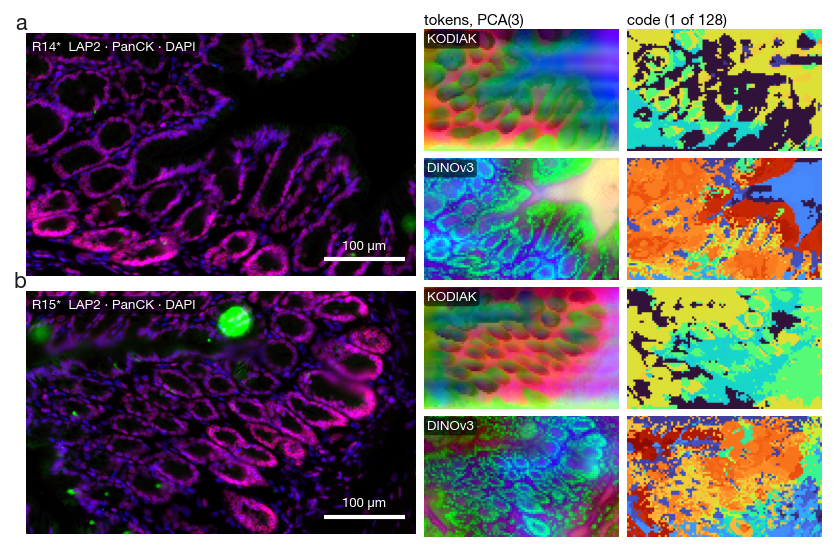

KODIAK   41/128 codes active on the test regions,   6 cover 90 % of tokens | PCA(3) explains 40% of token variance
DINOv3   86/128 codes active on the test regions,  38 cover 90 % of tokens | PCA(3) explains 28% of token variance


In [3]:
from sklearn.decomposition import PCA

for tag in ENC:                                                                # PCA(3) of each encoder's tokens, fit on all regions
    allt = np.concatenate([R[tag]["toks"].reshape(-1, D) for R in REG.values()])
    pca = PCA(3, random_state=0).fit(allt)
    lo, hi = np.percentile(pca.transform(allt), (2, 98), axis=0)
    for R in REG.values():
        h, w = R[tag]["codes"].shape
        R[tag]["pca"] = np.clip((pca.transform(R[tag]["toks"].reshape(-1, D)) - lo) / (hi - lo), 0, 1).reshape(h, w, 3)
    ENC[tag]["pca_var"] = pca.explained_variance_ratio_.sum()

fig = plt.figure(figsize=(7.6, 2.45 * len(SHOW)))
gs = fig.add_gridspec(2 * len(SHOW), 3, width_ratios=[2, 1, 1], wspace=0.03, hspace=0.05)
for r, key in enumerate(SHOW):
    R = REG[key]
    h, w = R["KODIAK"]["codes"].shape
    a = fig.add_subplot(gs[2 * r:2 * r + 2, 0])
    a.imshow(R["rgb"]); a.set_axis_off()
    chip(a, f"{short(key)}{'*' if R['has_qc'] else ''}  {' · '.join(MARKERS)}")
    scalebar(a, w * G, h * G)
    panel(a, "ab"[r], dx=0.0, dy=1.0)
    for i, tag in enumerate(ENC):
        for j, view in enumerate(("pca", "codes")):
            ax = fig.add_subplot(gs[2 * r + i, 1 + j])
            img = R[tag]["pca"] if view == "pca" else ENC[tag]["cmap"][R[tag]["codes"]]
            ax.imshow(img.repeat(G, 0).repeat(G, 1)); ax.set_axis_off()
            if j == 0:
                chip(ax, tag)
            if r == 0 and i == 0:
                ax.set_title(("tokens, PCA(3)", "code (1 of 128)")[j], fontsize=8, pad=3)
plt.show()

for tag in ENC:
    counts = np.bincount(TOK[f"code_{tag}"], minlength=128)
    cum = np.sort(counts)[::-1].cumsum() / counts.sum()
    print(f"{tag:7s} {(counts > 0).sum():3d}/128 codes active on the test regions, {int((cum < 0.9).sum()) + 1:3d} cover 90 % of tokens | "
          f"PCA(3) explains {ENC[tag]['pca_var']:.0%} of token variance")

**Figure 1 — The two held-out regions (the slide's validation regions R14 (a) and R15 (b)) through both encoders.** Left: the
input as analysed here — LAP2 red · PanCK green · DAPI blue, one of the pretraining draws (\* = QC-reviewed; bar 100 µm). Right, KODIAK's EMA teacher above and DINOv3
below: the patch tokens as their first three principal components rendered as RGB (fit per encoder on all held-out
regions — colors compare across regions, not across encoders), and the hard code of every 16-px token: the argmax
prototype for KODIAK, the nearest $k$-means centroid for DINOv3, hues following each codebook's clustered order of
Figure 2 so that similar codes share a color. Whatever repeats in a code map is what that codebook decided a "kind of
place" is; the printed counts say how much of each codebook is alive on unseen regions.

## 2. The codebook's geometry: code families

A token's code is the prototype (centroid) its projection is most aligned with, and codes that fire on similar content
end up with similar vectors — so a codebook has a geometry of its own that needs no label to read. Ward's clustering of
the unit vectors cut at $K{=}5$ gives each encoder's **families**: its own partition of the slide into kinds of place.

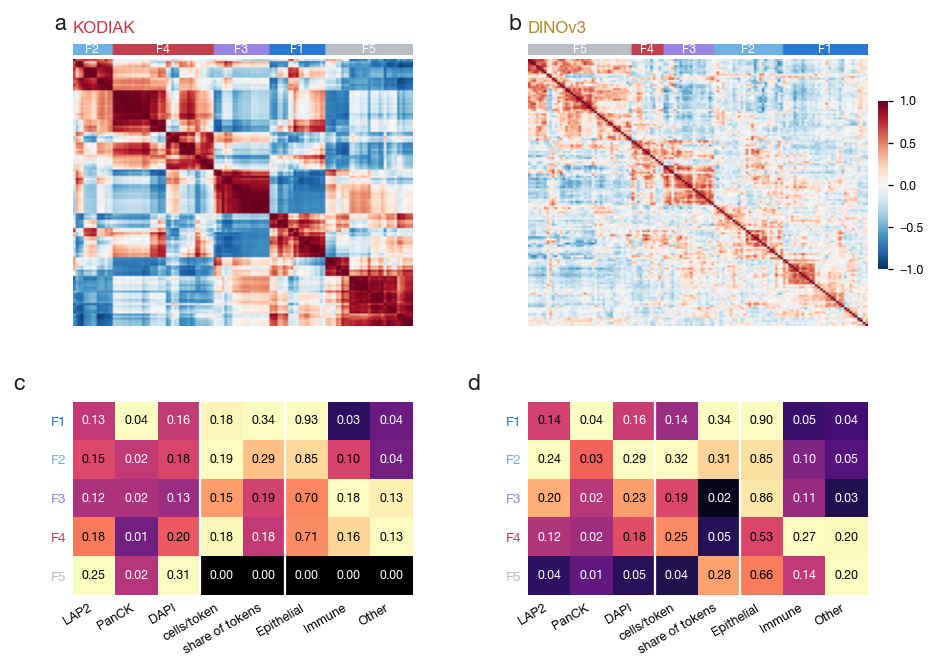

KODIAK  codes per family: F1 21 (3641 tokens), F2 15 (3158 tokens), F3 21 (2073 tokens), F4 38 (1915 tokens), F5 33 (1 tokens)
DINOv3  codes per family: F1 32 (3696 tokens), F2 26 (3371 tokens), F3 19 (187 tokens), F4 12 (564 tokens), F5 39 (2970 tokens)


In [4]:
def make_families(tag):
    """Ward families of a codebook, ranked for naming (F1 … most PanCK-rich to least; the sparsest used family last; a
    family whose codes never fire on the test regions last with zeros), with their profile over the annotated tokens."""
    E = ENC[tag]
    fam = fcluster(E["Z"], K_FAM, criterion="maxclust") - 1
    TOK[f"fam_{tag}"] = fam[TOK[f"code_{tag}"]]
    g = TOK.groupby(f"fam_{tag}")
    prof = g[MARKERS].mean().reindex(range(K_FAM)).fillna(0)
    prof["cells/token"] = g.n_cells.mean().reindex(range(K_FAM)).fillna(0)
    prof["tokens"] = TOK[f"fam_{tag}"].value_counts().reindex(range(K_FAM)).fillna(0).astype(int)
    used = [f for f in range(K_FAM) if prof.tokens[f] > 0]
    sparse = prof.loc[used, "cells/token"].idxmin()
    rank = [f for f in prof[GREEN].sort_values(ascending=False).index if f in used and f != sparse] + \
           [sparse] + [f for f in range(K_FAM) if f not in used]
    name = {f: f"F{i + 1}" for i, f in enumerate(rank)}
    fcolor = {f: PALETTE[i] for i, f in enumerate(rank)}
    c = TOK[TOK.n_cells > 0]
    comp = pd.crosstab(c[f"fam_{tag}"], c.pheno, normalize="index").reindex(index=rank, columns=CLASSES).fillna(0)
    summary = prof.loc[rank].copy()
    summary["share"] = summary.tokens / summary.tokens.sum()
    summary = summary[MARKERS + ["cells/token", "share"]].join(comp)
    summary.index = [name[f] for f in rank]
    TOK[f"family_{tag}"] = TOK[f"fam_{tag}"].map(name)
    E.update(fam=fam, rank=rank, name=name, fcolor=fcolor, frgb=np.stack([hex2rgb(fcolor[f]) for f in range(K_FAM)]),
             sparse=sparse, prof=prof, summary=summary)

for tag in ENC:
    make_families(tag)
cel = TOK[TOK.n_cells > 0]

fig = plt.figure(figsize=(7.6, 5.3))
gs = fig.add_gridspec(2, 2, height_ratios=[1.45, 1], hspace=0.32, wspace=0.34)
for i, tag in enumerate(ENC):
    E = ENC[tag]
    a = fig.add_subplot(gs[0, i])                                              # a, b - similarity, clustered, families on top
    im = a.imshow(E["SIM"][np.ix_(E["leaves"], E["leaves"])], cmap="RdBu_r", vmin=-1, vmax=1)
    strip = E["frgb"][E["fam"][E["leaves"]]]
    a.imshow(strip[None].repeat(5, 0), extent=(-0.5, 127.5, -7.5, -2.5), aspect="auto")
    a.set_xlim(-0.5, 127.5); a.set_ylim(127.5, -7.5); a.set_xticks([]); a.set_yticks([])
    for s_ in a.spines.values():
        s_.set_visible(False)
    for f in E["rank"]:
        pos = np.where(E["fam"][E["leaves"]] == f)[0]
        if len(pos):
            a.text(pos.mean(), -5, E["name"][f], ha="center", va="center", fontsize=6.6, color="white", fontweight="bold")
    a.set_title(tag, color=E["color"])
    panel(a, "ab"[i], dx=-0.02)
    if i == 1:
        cb = fig.colorbar(im, cax=a.inset_axes([1.03, 0.2, 0.03, 0.6]))
        cb.ax.tick_params(labelsize=6.5); cb.outline.set_visible(False)
    b = fig.add_subplot(gs[1, i])                                              # c, d - what the families contain
    heat(b, E["summary"].rename(columns={"share": "share of tokens"}))
    for t, f in zip(b.get_yticklabels(), E["rank"]):
        t.set_color(E["fcolor"][f]); t.set_fontweight("bold")
    b.axvline(len(MARKERS) - 0.5, color="white", lw=1.2); b.axvline(len(MARKERS) + 1.5, color="white", lw=1.2)
    panel(b, "cd"[i], dx=-0.14)
plt.show()
for tag in ENC:
    E = ENC[tag]
    print(f"{tag:7s} codes per family: " + ", ".join(f"{E['name'][f]} {int((E['fam'] == f).sum())} ({E['prof'].tokens[f]} tokens)" for f in E["rank"]))

**Figure 2 — Each codebook's own geometry and the families it yields.** (a, b) Cosine similarity between all pairs of
KODIAK prototypes (a) and DINOv3 $k$-means centroids (b) after removing each codebook's mean direction (DINOv3's
centroids all share one), ordered by Ward's hierarchical clustering of the centered unit vectors;
the strip marks the five families the dendrogram gives (Ward rather than average linkage, which peels off single
outlying codes before it splits the bulk). (c, d) What each family contains once the expert annotations are laid over
its tokens: mean marker content on the slide-level scale, cell density, share of all tokens, and the lineage
composition of the annotated cells inside. Families are named by rank only (F1 … richest in the green marker to poorest, the sparsest
used family last) — the heatmap is their definition, and F1 of one encoder is not F1 of the other. A blocky matrix
with distinct families means the codebook is organized by content; a uniform one means it is not.

## 3. What one code encodes — and what a family looks like

Every code in its clustered order: marker content, expert-cell density, the lineage of those cells, and usage. Along
the code axis the question is whether content changes in blocks that follow the families (compartments) or code by
code (something else); within a family, whether what separates its codes is density — "how crowded" encoded apart
from "what is expressed". Below, the families made visible as their top-activating crops.

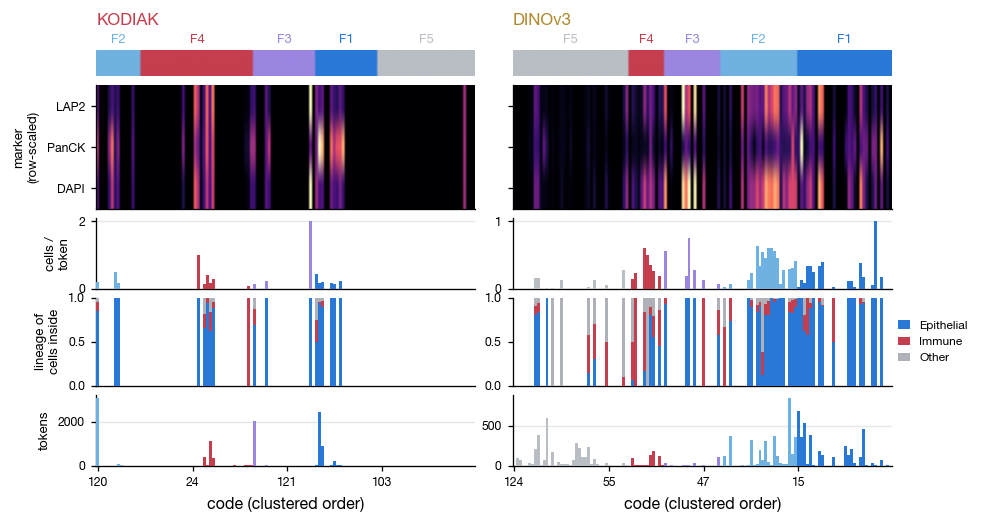

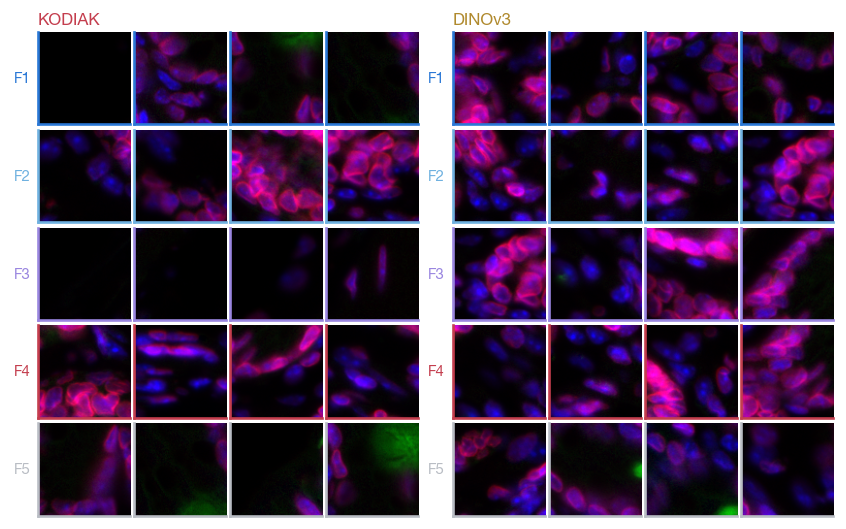

In [5]:
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(7.6, 4.0))
gs = GridSpec(5, 2, height_ratios=[0.3, 1.4, 0.8, 1.0, 0.8], hspace=0.12, wspace=0.1, figure=fig)
x = np.arange(128)
for i, tag in enumerate(ENC):
    E, col, oc = ENC[tag], f"code_{tag}", ENC[tag]["leaves"]
    per = TOK.groupby(col)
    mk = per[MARKERS].mean().reindex(range(128)).fillna(0)
    dens = per.n_cells.mean().reindex(range(128)).fillna(0)
    use = TOK[col].value_counts().reindex(range(128)).fillna(0)
    lin = pd.crosstab(cel[col], cel.pheno, normalize="index").reindex(index=range(128), columns=CLASSES).fillna(0)
    frgb = E["frgb"][E["fam"][oc]]
    a0 = fig.add_subplot(gs[0, i])                                             # family strip
    a0.imshow(frgb[None], aspect="auto", extent=(-0.5, 127.5, 0, 1)); a0.set_axis_off()
    for f in E["rank"]:
        pos = np.where(E["fam"][oc] == f)[0]
        if len(pos):
            a0.text(pos.mean(), 1.15, E["name"][f], ha="center", va="bottom", fontsize=7, color=E["fcolor"][f], fontweight="bold")
    a0.set_title(tag, color=E["color"], pad=13)
    a1 = fig.add_subplot(gs[1, i])                                             # marker content
    M = mk.values[oc].T
    a1.imshow(M / np.maximum(M.max(1, keepdims=True), 1e-9), cmap="magma", aspect="auto", vmin=0, vmax=1, extent=(-0.5, 127.5, 2.5, -0.5))
    a1.set_yticks(range(3), MARKERS if i == 0 else [""] * 3, fontsize=7.4); a1.set_xticks([])
    a2 = fig.add_subplot(gs[2, i])                                             # density
    a2.bar(x, dens.values[oc], width=1.0, color=frgb, zorder=3)
    a2.set_xlim(-0.5, 127.5); a2.set_xticks([]); ygrid(a2)
    a3 = fig.add_subplot(gs[3, i])                                             # lineage composition
    bottom = np.zeros(128)
    for c in CLASSES:
        v = lin[c].values[oc]
        a3.bar(x, v, bottom=bottom, width=1.0, color=PHENO_COLOR[c], zorder=3, label=c)
        bottom += v
    a3.set_xlim(-0.5, 127.5); a3.set_ylim(0, 1); a3.set_xticks([])
    a4 = fig.add_subplot(gs[4, i])                                             # usage
    a4.bar(x, use.values[oc], width=1.0, color=frgb, zorder=3)
    a4.set_xlim(-0.5, 127.5); a4.set_xlabel("code (clustered order)")
    a4.set_xticks(np.arange(0, 128, 32), [str(oc[k]) for k in range(0, 128, 32)], fontsize=6.5); ygrid(a4)
    if i == 0:
        a1.set_ylabel("marker\n(row-scaled)", fontsize=7); a2.set_ylabel("cells /\ntoken", fontsize=7)
        a3.set_ylabel("lineage of\ncells inside", fontsize=7); a4.set_ylabel("tokens", fontsize=7)
    else:
        a3.legend(ncol=1, fontsize=6.4, loc="center left", bbox_to_anchor=(1.003, 0.5), handlelength=1.0, borderaxespad=0.0)
    for a in (a1, a2, a3, a4):
        a.tick_params(axis="y", labelsize=6.5)
plt.show()

# ---- the families, seen: top-activating crops, four per family and encoder ------------------------------------------------
K_SHOW, HALF = 4, 48                                                           # 96 px = 31 µm: neighborhood scale
fig, ax = plt.subplots(K_FAM, 2 * K_SHOW + 1, figsize=(7.6, 0.93 * K_FAM),
                       gridspec_kw=dict(width_ratios=[1] * K_SHOW + [0.3] + [1] * K_SHOW, wspace=0.04, hspace=0.06))
for r in range(K_FAM):
    ax[r, K_SHOW].set_axis_off()
for i, tag in enumerate(ENC):
    E, c0 = ENC[tag], i * (K_SHOW + 1)
    for r, f in enumerate(E["rank"]):
        members = np.where(E["fam"] == f)[0]
        cand = []                                                              # (score, region, ty, tx)
        for key, R in REG.items():
            s = R[tag]["logits"][..., members].max(-1)
            h, w = s.shape
            flat = np.argsort(s.ravel())[::-1][:K_SHOW * 6]
            cand += [(s.ravel()[k], key, k // w, k % w) for k in flat]
        cand.sort(key=lambda t: -t[0])
        picked, seen = [], set()
        for sc, key, ty, tx in cand:                                           # spread the row over regions and places
            if any(k == key and abs(ty - a_) < 4 and abs(tx - b_) < 4 for k, a_, b_ in seen):
                continue
            picked.append((key, ty, tx)); seen.add((key, ty, tx))
            if len(picked) == K_SHOW:
                break
        for s, (key, ty, tx) in enumerate(picked):
            R = REG[key]
            cy, cx = ty * G + G // 2, tx * G + G // 2
            Hh, Ww = R["rgb"].shape[:2]
            y0, x0 = int(np.clip(cy - HALF, 0, Hh - 2 * HALF)), int(np.clip(cx - HALF, 0, Ww - 2 * HALF))
            ax[r, c0 + s].imshow(R["rgb"][y0:y0 + 2 * HALF, x0:x0 + 2 * HALF])
        for s in range(K_SHOW):
            a_ = ax[r, c0 + s]
            a_.set_xticks([]); a_.set_yticks([])
            for s_ in a_.spines.values():
                s_.set_edgecolor(E["fcolor"][f]); s_.set_linewidth(1.4)
        ax[r, c0].set_ylabel(E["name"][f], color=E["fcolor"][f], fontweight="bold", fontsize=8, rotation=0, ha="right", va="center", labelpad=4)
    ax[0, c0].set_title(tag, color=E["color"], pad=4)
plt.show()

**Figure 3 — What one code encodes.** Top: every code of each codebook in the clustered order of Figure 2 (family strip
on top): mean marker content (rows scaled to their maximum), expert cells per token, lineage composition of those
cells, and usage on the test regions — unused codes are the black columns. Bottom: each family made visible — the four
96-px crops (31 µm, neighborhood scale) that activate any of its codes most strongly anywhere on the held-out regions, frame
in the family's color; KODIAK left, DINOv3 right, rows ranked independently per encoder.

## 4. Families against the reference niches

The paper's niche pipeline needs boundaries, markers, gates and a cell graph; a family needs an image. On every token
that holds an expert cell, the families are compared with the niche of the cells inside.

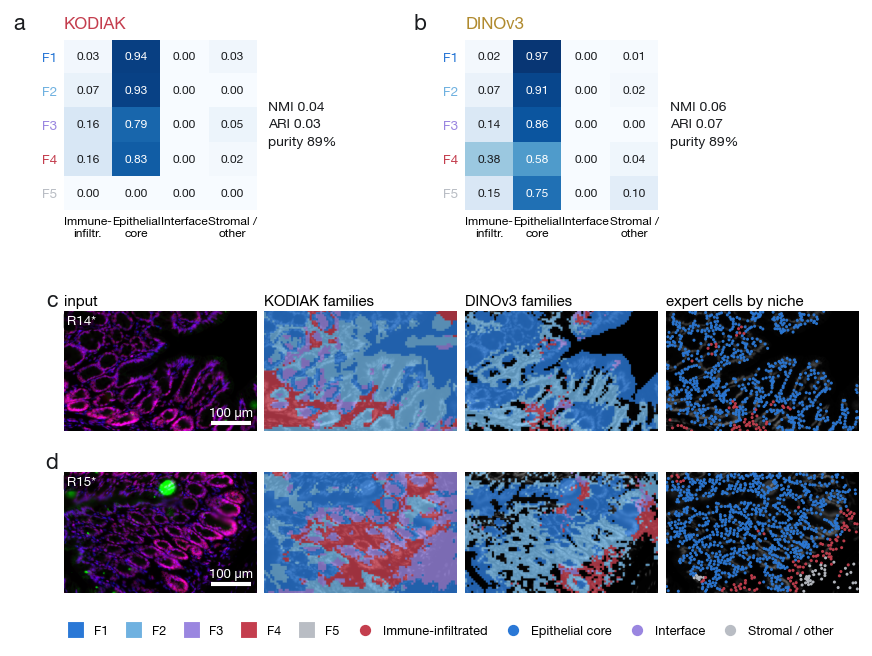

1887 tokens with an expert cell; KODIAK: sparse family F5 (0% of tokens) left gray on the maps | DINOv3: sparse family F5 (28% of tokens) left gray on the maps


In [6]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

CN = list(NICHE_COLOR)
AGREE = {}
for tag in ENC:
    E, fam = ENC[tag], cel[f"family_{tag}"]
    ct = pd.crosstab(fam, cel.niche, normalize="index").reindex(index=[E["name"][f] for f in E["rank"]], columns=CN).fillna(0)
    AGREE[tag] = dict(ct=ct, nmi=normalized_mutual_info_score(cel.niche, fam), ari=adjusted_rand_score(cel.niche, fam),
                      purity=pd.crosstab(fam, cel.niche).max(1).sum() / len(cel))

fig = plt.figure(figsize=(7.6, 2.3 + 1.2 * len(SHOW)))
top = 1.45 / (2.3 + 1.2 * len(SHOW))                                           # the matrices' share of the height
gs_a = fig.add_gridspec(1, 4, top=0.96, bottom=1 - top, wspace=0.04)
gs_b = fig.add_gridspec(len(SHOW), 4, top=1 - top - 0.14, bottom=0.07, hspace=0.12, wspace=0.04)
for i, tag in enumerate(ENC):                                                  # a, b - agreement matrices
    E, A = ENC[tag], AGREE[tag]
    a = fig.add_subplot(gs_a[0, 2 * i])
    ct = A["ct"]
    a.imshow(ct.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    a.set_xticks(range(4), ["Immune-\ninfiltr.", "Epithelial\ncore", "Interface", "Stromal /\nother"], fontsize=6.4)
    a.set_yticks(range(len(ct)), ct.index, fontsize=7.2)
    for t, f in zip(a.get_yticklabels(), E["rank"]):
        t.set_color(E["fcolor"][f]); t.set_fontweight("bold")
    for r_ in range(ct.shape[0]):
        for c_ in range(ct.shape[1]):
            a.text(c_, r_, f"{ct.values[r_, c_]:.2f}", ha="center", va="center", fontsize=6.4, color="white" if ct.values[r_, c_] > 0.5 else INK)
    for s_ in a.spines.values():
        s_.set_visible(False)
    a.tick_params(length=0)
    a.set_title(tag, color=E["color"])
    a.text(1.06, 0.5, f"NMI {A['nmi']:.2f}\nARI {A['ari']:.2f}\npurity {A['purity']:.0%}", transform=a.transAxes,
           fontsize=7.4, va="center", ha="left", color=INK, linespacing=1.6)
    panel(a, "ab"[i], dx=-0.2)
for r, key in enumerate(SHOW):                                                 # c, d - the maps
    R = REG[key]
    h, w = R["KODIAK"]["codes"].shape
    gray = np.repeat(R["rgb"].mean(-1, keepdims=True), 3, -1)
    e = expert[expert.region == key]
    axs = [fig.add_subplot(gs_b[r, c_]) for c_ in range(4)]
    axs[0].imshow(R["rgb"])
    for i, tag in enumerate(ENC):
        E = ENC[tag]
        fam_map = E["frgb"][E["fam"][R[tag]["codes"]]].repeat(G, 0).repeat(G, 1)
        cellular = (E["fam"][R[tag]["codes"]] != E["sparse"]).repeat(G, 0).repeat(G, 1)[..., None]   # the sparse family stays gray
        axs[1 + i].imshow(np.where(cellular, np.clip(0.3 * gray + 0.8 * fam_map, 0, 1), gray * 0.9))
    axs[3].imshow(gray * 0.6)
    axs[3].scatter(e.cx, e.cy, c=[NICHE_COLOR[n] for n in e.niche], s=2.6, lw=0, alpha=0.95)
    axs[3].set_xlim(0, w * G); axs[3].set_ylim(h * G, 0)
    for ax_ in axs:
        ax_.set_axis_off()
    chip(axs[0], f"{short(key)}{'*' if R['has_qc'] else ''}")
    scalebar(axs[0], w * G, h * G)
    if r == 0:
        for ax_, t in zip(axs, ("input", "KODIAK families", "DINOv3 families", "expert cells by niche")):
            ax_.set_title(t, fontsize=8, pad=3)
    panel(axs[0], "cd"[r], dx=-0.03, dy=1.0)
handles = [plt.Line2D([], [], marker="s", ls="", ms=7, color=PALETTE[k], label=f"F{k + 1}") for k in range(K_FAM)] + \
          [plt.Line2D([], [], marker="o", ls="", ms=5, color=v, label=k) for k, v in NICHE_COLOR.items()]
fig.legend(handles=handles, ncol=9, loc="lower center", bbox_to_anchor=(0.5, 0.0), fontsize=6.8, handletextpad=0.4, columnspacing=1.0)
plt.show()
print(f"{len(cel)} tokens with an expert cell; " + " | ".join(
    f"{tag}: sparse family {ENC[tag]['name'][ENC[tag]['sparse']]} ({ENC[tag]['prof'].tokens[ENC[tag]['sparse']] / len(TOK):.0%} of tokens) left gray on the maps" for tag in ENC))

**Figure 4 — Are the families the reference niches?** (a, b) For every token that holds an expert cell, the row-normalized
agreement between each encoder's family and the niche of the cells inside (the paper's four cellular neighborhoods:
10-cell windows over the gated expert cells, $k$-means); beside each matrix the normalized mutual information, adjusted
Rand index and purity (fraction of tokens whose family's majority niche is theirs). (c, d) The same on the map, for the
two held-out regions: input | KODIAK family per 16-px token | DINOv3 family | expert
cells colored by niche (bar 100 µm); the sparsest family of each encoder, the empty slide, is left gray. Family colors
are per encoder (F1 of one is not F1 of the other). A 16-px token is not a cell and the reference vocabulary is a
four-way cut of three lineages, so this is a ceiling of what the expert side can express, not a segmentation score.

## 5. What a token knows beyond its pixels

The input carries the markers, so a code that tracks PanCK or LAP2 has only read its pixels. The test is a probe on a
held-out **region**: leave one of the held-out regions out, fit a logistic regression on standardized features of the
others, score balanced accuracy on the left-out one.

/Users/marjan/miniforge3/envs/dl/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/Users/marjan/miniforge3/envs/dl/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/Users/marjan/miniforge3/envs/dl/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


probes done in 2 s — balanced accuracy (%), mean over the 2 held-out-region folds
features             marker pixels (6)  KODIAK code (1 of 128)  DINOv3 code (1 of 128)  KODIAK token (768)  DINOv3 token (768)
target                                                                                                                        
cell present                      76.0                    51.6                    70.4                76.7                71.7
lineage of the cell               61.1                    42.7                    35.9                55.2                52.6
niche of the cell                 52.9                    45.1                    53.0                60.2                56.7


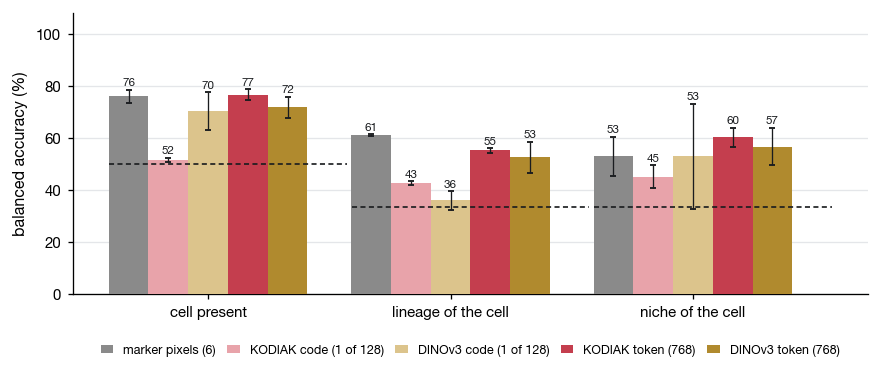

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

t0 = time.perf_counter()
FEATS = {"marker pixels (6)": TOK[MARKERS + [f"{m}_sd" for m in MARKERS]].values.astype(np.float32),
         "KODIAK code (1 of 128)": np.eye(128, dtype=np.float32)[TOK.code_KODIAK.values],
         "DINOv3 code (1 of 128)": np.eye(128, dtype=np.float32)[TOK.code_DINOv3.values],
         f"KODIAK token ({D})": np.concatenate([R["KODIAK"]["toks"].reshape(-1, D) for R in REG.values()]),
         f"DINOv3 token ({D})": np.concatenate([R["DINOv3"]["toks"].reshape(-1, D) for R in REG.values()])}
FCOLOR = dict(zip(FEATS, ["#8A8A8A", "#E8A3AA", "#DCC48C", ENC_COLOR["KODIAK"], ENC_COLOR["DINOv3"]]))
assert all(len(v) == len(TOK) for v in FEATS.values())
has = (TOK.n_cells > 0).values
TARGETS = {"cell present": ((TOK.n_cells > 0).astype(int).values, np.ones(len(TOK), bool)),
           "lineage of the cell": (TOK.pheno.values, has), "niche of the cell": (TOK.niche.values, has)}
rng = np.random.default_rng(0)
res = []
for tname, (y, m) in TARGETS.items():
    for held in REG:
        te = m & (TOK.region.values == held)
        tr = m & (TOK.region.values != held)
        tr_idx = np.where(tr)[0]
        if len(tr_idx) > 6000:                                                 # enough for a linear probe, keeps this cell quick
            tr_idx = rng.choice(tr_idx, 6000, replace=False)                   # one draw per fold, shared by every feature set
        for fname, X in FEATS.items():
            clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.1, class_weight="balanced"))
            clf.fit(X[tr_idx], y[tr_idx])
            res.append({"target": tname, "features": fname, "held_out": short(held),
                        "balanced_acc": balanced_accuracy_score(y[te], clf.predict(X[te]))})
res = pd.DataFrame(res)
tab = res.groupby(["target", "features"]).balanced_acc.mean().unstack("features")[list(FEATS)].loc[list(TARGETS)]
print(f"probes done in {time.perf_counter() - t0:.0f} s — balanced accuracy (%), mean over the {len(REG)} held-out-region folds\n" + (100 * tab).round(1).to_string())

fig, a = plt.subplots(figsize=(7.6, 2.7))
xx = np.arange(len(TARGETS))
wdt = 0.82 / len(FEATS)
for i, fname in enumerate(FEATS):
    mu = res[res.features == fname].groupby("target").balanced_acc.mean().loc[list(TARGETS)]
    sd = res[res.features == fname].groupby("target").balanced_acc.std().loc[list(TARGETS)]
    a.bar(xx + i * wdt, 100 * mu, wdt, color=FCOLOR[fname], zorder=3, label=fname)
    a.errorbar(xx + i * wdt, 100 * mu, 100 * sd, fmt="none", ecolor=INK, elinewidth=0.7, capsize=1.5, zorder=4)
    for j, (v, e_) in enumerate(zip(mu, sd)):
        a.text(xx[j] + i * wdt, 100 * (v + e_) + 1.5, f"{100 * v:.0f}", ha="center", fontsize=6.2, color=INK)
for j, (tname, (y, m)) in enumerate(TARGETS.items()):
    k = len(np.unique(y[m]))
    a.hlines(100 / k, xx[j] - 0.08, xx[j] + 0.9, color=INK, lw=0.9, ls=(0, (3, 2)), zorder=5)
a.set_xticks(xx + 2 * wdt, list(TARGETS))
a.set_ylabel("balanced accuracy (%)")
a.set_ylim(0, 108)
a.legend(ncol=5, fontsize=6.7, loc="upper center", bbox_to_anchor=(0.5, -0.14), handlelength=1.0, columnspacing=0.9)
ygrid(a)
plt.show()

**Figure 5 — Per-token linear probes with a held-out region.** For every 16-px token, predict whether it holds an expert
cell, the lineage of that cell, and its reference niche, from five descriptions of the same token: the marker pixels
themselves (mean and spread of each marker), each encoder's hard code (one symbol of 128) and each encoder's 768-d
token; logistic regression on standardized features, trained on all but one held-out region and scored on that one
(mean ± s.d. over the folds; dashed = chance). The gaps carry the reading: a token above the marker pixels has
inferred context the intensities do not state; a token below them has discarded information the input holds — the
DINO color augmentations act on an image whose color *is* the marker identity, a finding about the recipe, not the
tissue; KODIAK against DINOv3, on identical windows, is what continued pretraining on this slide added or removed.

## 6. The CLS token at slide scale

KODIAK's second objective aligns the CLS token across global and local crops of a patch in prototype space; DINOv3's
CLS comes from the image-level DINO objective on natural images. Every kept patch of the slide — 1,750, all splits — is
encoded by both, the CLS embeddings clustered ($K{=}5$, $k$-means on unit vectors) and drawn back at the patches' positions.

In [8]:
# from sklearn.cluster import KMeans
# from kodiak import MultiCropPrototypeCLSLoss

# pt = pd.read_csv(DEFAULT_DATASET / "patches.csv")
# pt = pt[pt.kept.astype(bool) & (pt.slide == SLIDE)].reset_index(drop=True)
# t0 = time.perf_counter()
# CLS, prof_l = {tag: [] for tag in ENC}, []
# for i in range(0, len(pt), 16):
#     rows = pt.iloc[i:i + 16]
#     stacks = [mx.read_region(Box(int(r.x0), int(r.y0), int(r.x1), int(r.y1)), markers=MARKERS, level=0) for r in rows.itertuples()]
#     xb = torch.from_numpy(np.stack([to_input(composite(s)) for s in stacks]))
#     for tag in ENC:
#         CLS[tag].append(ENC[tag]["cls"](xb).numpy())
#     prof_l.append(np.stack([marker01(s).mean((1, 2)) for s in stacks]))
# CLS = {tag: np.concatenate(v) for tag, v in CLS.items()}
# PROF = pd.DataFrame(np.concatenate(prof_l), columns=MARKERS)
# print(f"{len(pt)} patches x 2 encoders in {time.perf_counter() - t0:.0f} s")

# for tag in ENC:
#     Cn = CLS[tag] / np.linalg.norm(CLS[tag], axis=1, keepdims=True)
#     kmc = KMeans(K_CLS, n_init=10, random_state=0).fit(Cn)
#     pt[f"cluster_{tag}"] = kmc.labels_
#     cprof = PROF.groupby(kmc.labels_).mean()
#     cprof["DAPI fg"] = pt.groupby(f"cluster_{tag}").fg_fraction.mean()
#     cprof["patches"] = pt[f"cluster_{tag}"].value_counts()
#     csparse = cprof["DAPI fg"].idxmin()
#     crank = [c for c in cprof[GREEN].sort_values(ascending=False).index if c != csparse] + [csparse]
#     ENC[tag].update(cprof=cprof, crank=crank, cname={c: f"C{i + 1}" for i, c in enumerate(crank)},
#                     ccolor={c: PALETTE[i] for i, c in enumerate(crank)})

# thumb, ds = mx.thumbnail(max_dim=1400, markers=MARKERS)
# timg = composite(thumb).transpose(1, 2, 0)
# fig = plt.figure(figsize=(7.6, 5.0))
# gs = fig.add_gridspec(2, 2, height_ratios=[1.65, 1], hspace=0.2, wspace=0.08)
# for i, tag in enumerate(ENC):
#     E = ENC[tag]
#     a = fig.add_subplot(gs[0, i])                                              # a, b - the slide, patches by CLS cluster
#     a.imshow(np.clip(timg * 3.0, 0, 1))
#     sz = max(1.0, 256 / ds)
#     for c in E["crank"]:
#         s_ = pt[pt[f"cluster_{tag}"] == c]
#         a.scatter((s_.x0 + 128) / ds, (s_.y0 + 128) / ds, marker="s", s=sz ** 2 * 0.5, color=E["ccolor"][c], lw=0, alpha=0.9,
#                   label=f"{E['cname'][c]} ({len(s_)})")
#     a.set_axis_off()
#     chip(a, tag)
#     a.legend(loc="lower left", fontsize=6.4, markerscale=1.1, handletextpad=0.3, labelcolor="white", facecolor="black", framealpha=0.5, frameon=True)
#     panel(a, "ab"[i], dx=-0.01, dy=1.0)
#     b = fig.add_subplot(gs[1, i])                                              # c, d - cluster profiles
#     heat(b, E["cprof"].loc[E["crank"]].rename(index=E["cname"]))
#     for t, c in zip(b.get_yticklabels(), E["crank"]):
#         t.set_color(E["ccolor"][c]); t.set_fontweight("bold")
#     panel(b, "cd"[i], dx=-0.16, dy=1.04)
# plt.show()

# pcl = MultiCropPrototypeCLSLoss(embed_dim=D, num_prototypes=kodiak.num_prototypes)
# pcl.load_state_dict({k.split("prototype_cls_loss.", 1)[1]: v for k, v in ck["state_dict"].items()
#                      if k.startswith("prototype_cls_loss.")}, strict=False)
# cls_codes = pcl.cls_prototype_head(torch.from_numpy(CLS["KODIAK"])).argmax(-1).numpy()
# print(f"KODIAK CLS codebook: {len(np.unique(cls_codes))}/128 prototypes used by the {len(pt)} patches (top code holds {np.bincount(cls_codes).max() / len(pt):.0%})")
# print(f"agreement of the two CLS clusterings: ARI {adjusted_rand_score(pt.cluster_KODIAK, pt.cluster_DINOv3):.2f}; patches per KODIAK cluster (rows) and DINOv3 cluster (columns):")
# print(pd.crosstab(pt.cluster_KODIAK.map(ENC["KODIAK"]["cname"]), pt.cluster_DINOv3.map(ENC["DINOv3"]["cname"]))
#       .loc[[ENC["KODIAK"]["cname"][c] for c in ENC["KODIAK"]["crank"]], [ENC["DINOv3"]["cname"][c] for c in ENC["DINOv3"]["crank"]]].to_string())

**Figure 6 — The CLS token at slide scale.** (a, b) Every kept 256² patch of the slide, colored by its CLS cluster under
KODIAK (a) and DINOv3 (b), on the slide thumbnail (brightened 3×); (c, d) the clusters' mean marker content, DAPI
foreground fraction and size. Clusters are ranked per encoder as the families were (C1 … most PanCK-rich to least, the
emptiest last). Contiguous territories with distinct profiles mean the token sorts tissue by kind; the printed table
says how far the two encoders sort it the same way, and how many of KODIAK's 128 CLS prototypes the alignment loss
ended up using.

## Reading the figures

Everything above is read at the epoch printed by the first cell — rerun at the final checkpoint before quoting.

- **Figure 1** — does the code map repeat the architecture of the input (nests, infiltrate, stroma, empty slide as
  their own codes), and is more or less of the codebook alive on unseen regions after pretraining on the slide?
- **Figures 2–3** — are the codes organized into families that read, in expert terms, as marker compartments with
  density graded inside them — or as texture / density families that ignore the marker color? Same question for the
  $k$-means families of the foundation.
- **Figure 4** — how much of the reference niche vocabulary each encoder's families recover (NMI, purity), and where
  the maps disagree, why.
- **Figure 5** — the two gaps: pixels vs token, and DINOv3 vs KODIAK on identical windows.
- **Figure 6** — whether the CLS token sorts the slide into contiguous territories of distinct marker profile, and
  whether the two encoders sort it alike.

One slide, its held-out regions: this demonstrates the reading, not a population claim.

---
**References.** Schürch et al., *Coordinated Cellular Neighborhoods Orchestrate Antitumoral Immunity at the
Colorectal Cancer Invasive Front*, Cell 2020 — cellular neighborhoods. Keren et al., Cell 2018 — mixed /
compartmentalized tumor-immune architectures. Caron et al., SwAV, NeurIPS 2020 — Sinkhorn-balanced prototype
assignment. Zhou et al., iBOT, ICLR 2022 — masked prototype prediction. Oquab et al., DINOv2, TMLR 2024 and
Siméoni et al., DINOv3, 2025 — the backbone and its multi-crop CLS objective.